In [16]:
from bikes_data import make_rentals

# Generate the reproducible dataset
df = make_rentals()

# Display the first five rows
print(df.head())

# Display descriptive statistics
print(df["rentals"].describe().round(2))

   hour  temperature_c  rain_mm  wind_kph  is_weekend station_type  rentals
0    20           28.9      0.0      10.9           1  residential        4
1     4           22.8      0.0       5.9           0         park        1
2     0           13.6      3.0      15.9           0         park        0
3    15            9.6      0.0      26.0           1  residential       13
4     8            7.4      3.0       9.8           0         park        0
count    6000.00
mean       10.59
std        14.17
min         0.00
25%         2.00
50%         5.00
75%        13.00
max       105.00
Name: rentals, dtype: float64


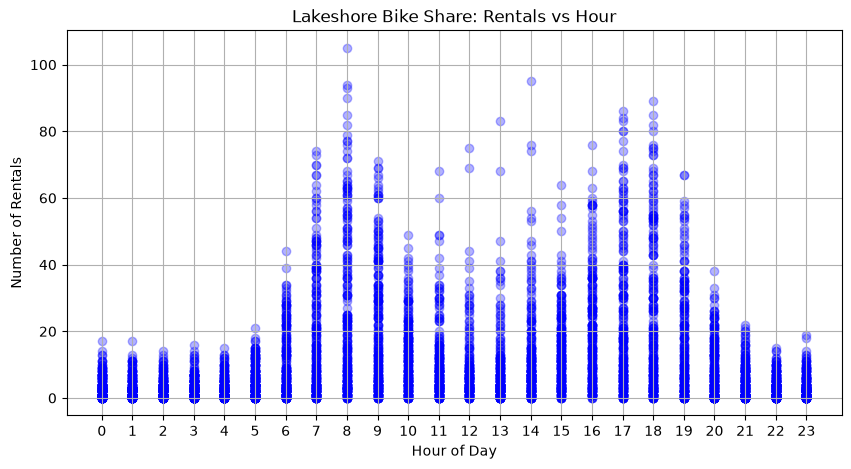

In [17]:
import matplotlib.pyplot as plt

# Plot rentals against the hour
plt.figure(figsize=(10, 5))

plt.scatter(df["hour"], df["rentals"], alpha=0.3, color="blue")

plt.xlabel("Hour of Day")
plt.ylabel("Number of Rentals")
plt.title("Lakeshore Bike Share: Rentals vs Hour")

plt.xticks(range(24))
plt.grid(True)

plt.show()

In [18]:
from sklearn.model_selection import train_test_split

# Fixed random seed
RANDOM_STATE = 42

# First split: 60% training, 40% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.40,
    random_state=RANDOM_STATE
)

# Second split: divide temporary data equally
# 20% validation and 20% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=RANDOM_STATE
)

# Verify split sizes
print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))

Training rows: 3600
Validation rows: 1200
Test rows: 1200


In [19]:
import torch
import numpy as np
from torch.utils.data import Dataset, DataLoader

In [20]:
class BikeRentalDataset(Dataset):
    def __init__(self, X, y):
        # Convert features to float32 tensors
        self.X = torch.tensor(
            np.asarray(X, dtype=np.float32),
            dtype=torch.float32
        )

        # Convert targets to float32 tensors
        self.y = torch.tensor(
            np.asarray(y, dtype=np.float32).reshape(-1, 1),
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [23]:
from bikes_data import make_rentals
from sklearn.model_selection import train_test_split

# Fixed seed for reproducibility
RANDOM_STATE = 42

# Load the dataset
df = make_rentals()

# Split 60% training, 40% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.40,
    random_state=RANDOM_STATE
)

# Split remaining 40% into validation and test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=RANDOM_STATE
)

# Separate features and target
X_train = train_df.drop(columns=["rentals"])
y_train = train_df["rentals"]

X_val = val_df.drop(columns=["rentals"])
y_val = val_df["rentals"]

X_test = test_df.drop(columns=["rentals"])
y_test = test_df["rentals"]

# Verify sizes
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (3600, 6)
Validation: (1200, 6)
Test: (1200, 6)


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Define features
numeric_features = [
    "hour",
    "temperature_c",
    "rain_mm",
    "wind_kph",
    "is_weekend"
]

categorical_features = ["station_type"]

# Create preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ],
    sparse_threshold=0
)

# Fit preprocessing on TRAINING data only
X_train_prepared = preprocessor.fit_transform(X_train)

# Transform validation and test data
X_val_prepared = preprocessor.transform(X_val)
X_test_prepared = preprocessor.transform(X_test)

print("Training:", X_train_prepared.shape)
print("Validation:", X_val_prepared.shape)
print("Test:", X_test_prepared.shape)

Training: (3600, 8)
Validation: (1200, 8)
Test: (1200, 8)


In [25]:
train_dataset = BikeRentalDataset(X_train_prepared, y_train)
val_dataset = BikeRentalDataset(X_val_prepared, y_val)
test_dataset = BikeRentalDataset(X_test_prepared, y_test)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Training: 3600
Validation: 1200
Test: 1200


In [27]:
from torch.utils.data import DataLoader

# Set batch size
BATCH_SIZE = 32

# Training DataLoader - shuffle enabled
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

# Validation DataLoader - no shuffling
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Test DataLoader - no shuffling
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("All three DataLoaders created successfully!")

All three DataLoaders created successfully!


In [29]:
import torch
from torch.utils.data import RandomSampler, SequentialSampler

# Verify individual observations
for dataset in [train_dataset, val_dataset, test_dataset]:
    X, y = dataset[0]
    assert X.dtype == torch.float32
    assert y.dtype == torch.float32

# Verify DataLoader shuffling
assert isinstance(train_loader.sampler, RandomSampler)
assert isinstance(val_loader.sampler, SequentialSampler)
assert isinstance(test_loader.sampler, SequentialSampler)

# Verify training batch
X_batch, y_batch = next(iter(train_loader))

assert X_batch.shape == (32, 8)
assert y_batch.shape == (32, 1)

print("All Dataset and DataLoader tests passed!")

print("All Dataset and DataLoader tests passed!")

All Dataset and DataLoader tests passed!
All Dataset and DataLoader tests passed!
